# ROBT407: Dropout for Fashion-MNIST clothing classification

**Research question:** Does adding dropout to a small CNN classification head improve macro-F1 on unseen clothing images? Which garments remain difficult?

This notebook is the experiment entry point. Source cells and the hypothesis were written before model fitting. `train` fits all models; `verify` replays saved evidence and checks every checkpoint against its saved test predictions. All ten categories are included. Team names and member contributions will be completed by the team before submission.

## 1. Prediction and fixed protocol (recorded before training)

**Hypothesis:** Head dropout at **p = 0.30** will increase mean held-out macro-F1 by reducing co-adaptation of the 64 hidden head features and the tendency of the dense head to fit training-specific details. The effect may be small: a compact CNN and a large training set can limit overfitting, while dropout can slow learning within a fixed budget. A negative or seed-dependent result remains valid.

**One change:** the dropout probability between the head ReLU and final linear layer changes from 0 to 0.30. Trainable layers and parameter counts stay identical. Both variants start from paired identical weights and use an independent shuffle generator for identical minibatch order. Fixed: split seed 407, pixel preprocessing, Adam learning rate 0.001, no weight decay or augmentation, batch size 128, 12 epochs, and highest validation macro-F1 checkpoint (earliest tie). Seeds: 11, 22, 33. No CNN hyperparameter search is conducted: one prescribed setting per variant and three training repeats. Logistic regression tunes C in {0.01, 0.1, 1} on the same validation set.

**Judgment:** primary metric is macro-F1, the unweighted mean of ten per-class F1 scores. Report all seeds, sample standard deviations (ddof=1), and each paired difference (dropout minus CNN). A positive mean is directional support in this fixed experiment; inconsistent signs weaken it. Three seeds describe training variation, not population significance. Accuracy and balanced accuracy are secondary metrics. Test metrics are computed only after every model and checkpoint is frozen. Representative CNN error plots use seed 11, chosen here before seeing results.

**Inclusion and duplicate rules:** retain every official test example. Hash raw image pixels; remove development images with a hash present in test, remove conflicting-label development groups, and keep the first original index of every remaining exact duplicate group. Create one stratified 80/20 train/validation split of the remaining training pool. No object IDs are available. Internal official test duplicates remain and are disclosed. Near duplicates are outside the exact-hash audit. Fit a single global pixel mean and standard deviation on training images only.

In [1]:
from pathlib import Path
import os, json, pandas as pd, numpy as np
from IPython.display import display, Image
from src.study import Study, verify_saved
from src.data import LABELS
ROOT = Path.cwd()
MODE = os.environ.get('FASHION_MODE', 'train')
print('Mode:', MODE)
print(json.dumps(json.loads((ROOT/'config.json').read_text()), indent=2))
study = Study(ROOT)
display(study.hardware())

Mode: verify
{
  "dataset": "Fashion-MNIST original IDX release (2017), MD5 verified",
  "split_seed": 407,
  "validation_fraction": 0.2,
  "seeds": [
    11,
    22,
    33
  ],
  "dropout": 0.3,
  "epochs": 12,
  "batch_size": 128,
  "learning_rate": 0.001,
  "optimizer": "Adam",
  "weight_decay": 0.0,
  "checkpoint_rule": "highest validation macro-F1, earliest epoch breaks ties",
  "baseline_C": [
    0.01,
    0.1,
    1.0
  ],
  "baseline_max_iter": 5000,
  "baseline_tol": 0.0001,
  "threads": 4,
  "device": "cpu",
  "primary_metric": "macro-F1",
  "duplicate_policy": "Preserve full official test set. Exclude development hashes present in test. Exclude conflicting-label development hash groups. Keep lowest original index per remaining exact-image hash. Then fixed stratified split."
}


{'python': '3.14.2 (v3.14.2:df793163d58, Dec  5 2025, 12:18:06) [Clang 16.0.0 (clang-1600.0.26.6)]',
 'platform': 'macOS-26.5.2-arm64-arm-64bit-Mach-O',
 'processor': 'arm',
 'logical_cpus': 10,
 'torch_threads': 4,
 'device': 'cpu',
 'cuda_available': False,
 'mps_available': True,
 'versions': {'torch': '2.15.0',
  'scikit-learn': '1.9.1',
  'numpy': '2.5.5',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'ipykernel': '7.4.0'},
 'cpu_model': 'Apple M4',
 'memory_bytes': '17179869184'}

## 2. Data provenance and partition audit

Fashion-MNIST: Xiao, Rasul and Vollgraf (2017), arXiv:1708.07747v2, https://arxiv.org/abs/1708.07747. Original IDX files: https://github.com/zalandoresearch/fashion-mnist. Download with `python scripts/download_data.py`; the loader checks the authors' four MD5 values. This identifies the original release by content rather than a changing repository branch. We implement the IDX loader locally and do not reuse a tutorial training script. The training loop follows standard PyTorch practices described in https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html. Dropout rationale: Srivastava et al., JMLR 15 (2014), https://jmlr.org/papers/v15/srivastava14a.html.

The following summary records missing-data checks, label mapping, exact duplicates and every class count. Test image hashing is a contamination check, not performance-based selection.

In [2]:
display(study.d['audit'])
display(pd.DataFrame(study.d['audit']['class_counts'], index=LABELS))
print('Training-only normalization:', study.d['mean'], study.d['std'])

{'dataset': 'Fashion-MNIST 2017 original release',
 'source': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/',
 'md5': {'train-images-idx3-ubyte.gz': '8d4fb7e6c68d591d4c3dfef9ec88bf0d',
  'train-labels-idx1-ubyte.gz': '25c81989df183df01b3e8a0aad5dffbe',
  't10k-images-idx3-ubyte.gz': 'bef4ecab320f06d8554ea6380940ec79',
  't10k-labels-idx1-ubyte.gz': 'bb300cfdad3c16e7a12a480ee83cd310'},
 'labels': {0: 'T-shirt/top',
  1: 'Trouser',
  2: 'Pullover',
  3: 'Dress',
  4: 'Coat',
  5: 'Sandal',
  6: 'Shirt',
  7: 'Sneaker',
  8: 'Bag',
  9: 'Ankle boot'},
 'original_train': 60000,
 'official_test': 10000,
 'counts': {'train': 48000, 'validation': 12000, 'test': 10000},
 'class_counts': {'original_train': [6000,
   6000,
   6000,
   6000,
   6000,
   6000,
   6000,
   6000,
   6000,
   6000],
  'train': [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800],
  'validation': [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200],
  'test': [10

,original_train,train,validation,test
T-shirt/top,6000,4800,1200,1000
Trouser,6000,4800,1200,1000
Pullover,6000,4800,1200,1000
Dress,6000,4800,1200,1000
Coat,6000,4800,1200,1000
Sandal,6000,4800,1200,1000
Shirt,6000,4800,1200,1000
Sneaker,6000,4800,1200,1000
Bag,6000,4800,1200,1000
Ankle boot,6000,4800,1200,1000


Training-only normalization: 0.28588689913465387 0.3529352823291432


## 3. Implementation and sanity checks

Input N×1×28×28; Conv(1,16,3,pad=1), ReLU, MaxPool(2); Conv(16,32,3,pad=1), ReLU, MaxPool(2); flatten 1568; Linear(1568,64), ReLU, Dropout(p), Linear(64,10). Cross-entropy consumes raw logits and int64 class targets. `train()` enables dropout; evaluation uses `eval()` and `inference_mode()`. Each minibatch clears gradients, computes logits and loss, backpropagates, then applies Adam. Checkpoints use validation only. The subset-learning check uses 64 training images and is discarded afterward.

In [3]:
from src.study import SmallCNN
print(SmallCNN())
if MODE == 'train': display(study.checks())
else: display(json.loads((ROOT/'results/checks.json').read_text()))

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


{'status': 'PASS',
 'input_shape': [64, 1, 28, 28],
 'output_shape': [64, 10],
 'labels': 'int64, 0..9',
 'finite_loss': 2.3205764293670654,
 'finite_gradients': True,
 'subset_samples': 64,
 'subset_steps': 180,
 'subset_accuracy': 1.0,
 'subset_final_loss': 0.000649340043310076,
 'paired_initial_weights_equal': True,
 'dropout_off_in_eval': True,
 'dropout_stochastic_in_train': True,
 'parameters': 105866,
 'layer_shapes': {'features.0': [64, 16, 28, 28],
  'features.1': [64, 16, 28, 28],
  'features.2': [64, 16, 14, 14],
  'features.3': [64, 32, 14, 14],
  'features.4': [64, 32, 14, 14],
  'features.5': [64, 32, 7, 7],
  'head.0': [64, 1568],
  'head.1': [64, 64],
  'head.2': [64, 64],
  'head.3': [64, 64],
  'head.4': [64, 10]}}

## 4. Classical baseline and validation selection
Multinomial logistic regression uses flattened normalized pixels and L2 regularization. All three C candidates must converge before the protocol can freeze. A pre-test setup run hit the original 500-iteration cap for C=0.1 and C=1; the common cap was raised to 5000 and all candidates rerun. These three initial fits and their times are disclosed in results/development_log.json; the CNN protocol stayed fixed. Training uses only the training partition, without refitting on validation.

In [4]:
if MODE == 'train': display(study.baseline())
else: display(pd.DataFrame(json.loads((ROOT/'results/baseline_tuning.json').read_text())['candidates']))

,C,seconds,iterations,converged,accuracy,macro_f1,balanced_accuracy
0,0.01,5.394469,484,True,0.860083,0.859561,0.860083
1,0.10,5.843002,510,True,0.854417,0.853618,0.854417
2,1.00,12.615055,1112,True,0.845583,0.844896,0.845583


## 5. Paired CNN training
Every run receives the full 12-epoch budget. We retain the checkpoint with the largest validation macro-F1. Online training loss/F1 use changing weights and active dropout; validation uses fixed epoch-end weights and dropout off, so their gap is descriptive rather than an exact like-for-like generalization gap.

In [5]:
if MODE == 'train': display(study.train_cnns())
else: display(pd.read_csv(ROOT/'results/training_runs.csv'))

,variant,seed,dropout,selected_epoch,val_macro_f1,train_seconds,epochs,parameters
0,cnn,11,0.0,12,0.918106,56.428645,12,105866
1,cnn,22,0.0,12,0.916438,57.012667,12,105866
2,cnn,33,0.0,12,0.917972,74.194598,12,105866
3,dropout,11,0.3,9,0.915968,64.419851,12,105866
4,dropout,22,0.3,12,0.915570,85.156361,12,105866
5,dropout,33,0.3,12,0.913270,82.721498,12,105866


## 6. Freeze before test evaluation
Save the chosen settings, checkpoints, split and source hashes before computing any test metric. Reusing saved predictions in verification does not select models or change settings.

In [6]:
if MODE == 'train':
    frozen = study.freeze()
    print('Procedure frozen at', frozen['frozen_at_utc'])
    display(study.evaluate())
else:
    display(json.loads((ROOT/'results/frozen_protocol.json').read_text())['selected_cnns'])
    display(pd.read_csv(ROOT/'results/comparison.csv'))

[{'variant': 'cnn',
  'seed': 11,
  'dropout': 0.0,
  'selected_epoch': 12,
  'val_macro_f1': 0.9181057130691697,
  'train_seconds': 56.42864549998194,
  'epochs': 12,
  'parameters': 105866},
 {'variant': 'cnn',
  'seed': 22,
  'dropout': 0.0,
  'selected_epoch': 12,
  'val_macro_f1': 0.9164383192377784,
  'train_seconds': 57.01266729226336,
  'epochs': 12,
  'parameters': 105866},
 {'variant': 'cnn',
  'seed': 33,
  'dropout': 0.0,
  'selected_epoch': 12,
  'val_macro_f1': 0.9179719497490136,
  'train_seconds': 74.19459787523374,
  'epochs': 12,
  'parameters': 105866},
 {'variant': 'dropout',
  'seed': 11,
  'dropout': 0.3,
  'selected_epoch': 9,
  'val_macro_f1': 0.9159676501744437,
  'train_seconds': 64.41985054127872,
  'epochs': 12,
  'parameters': 105866},
 {'variant': 'dropout',
  'seed': 22,
  'dropout': 0.3,
  'selected_epoch': 12,
  'val_macro_f1': 0.9155704462768778,
  'train_seconds': 85.1563605829142,
  'epochs': 12,
  'parameters': 105866},
 {'variant': 'dropout',
  'se

,run,variant,seed,selected_epoch,train_seconds,parameters,accuracy,macro_f1,balanced_accuracy
0,logistic,logistic,NaN,NaN,5.394469,7850,0.8452,0.844119,0.8452
1,cnn_11,cnn,11.0,12.0,56.428645,105866,0.9103,0.909230,0.9103
2,cnn_22,cnn,22.0,12.0,57.012667,105866,0.9094,0.909458,0.9094
3,cnn_33,cnn,33.0,12.0,74.194598,105866,0.9097,0.909133,0.9097
4,dropout_11,dropout,11.0,9.0,64.419851,105866,0.9066,0.906009,0.9066
5,dropout_22,dropout,22.0,12.0,85.156361,105866,0.9096,0.908726,0.9096
6,dropout_33,dropout,33.0,12.0,82.721498,105866,0.9076,0.906455,0.9076


## 7. Reproduce numbers and inspect evidence
Metrics below are recomputed from saved official-test predictions. Mean and sample SD aggregate training seeds, not independent test samples. Every model sees the same 10,000 indices.

In [7]:
from src.analysis import build_analysis
display(verify_saved(ROOT, check_checkpoints=True))
build_analysis(ROOT)
display(pd.read_csv(ROOT/'results/summary.csv'))
display(pd.read_csv(ROOT/'results/matched_seed_deltas.csv'))

{'status': 'PASS',
 'frozen_hashes_match': True,
 'prediction_rows': 10000,
 'runs_recomputed': ['logistic',
  'cnn_11',
  'cnn_22',
  'cnn_33',
  'dropout_11',
  'dropout_22',
  'dropout_33'],
 'all_metrics_match_at_1e_12': True,
 'checkpoint_predictions_identical': True}

,variant,runs,parameters,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,balanced_accuracy_sd,train_seconds_mean,train_seconds_sd
0,logistic,1,7850,0.845200,NaN,0.844119,NaN,0.845200,NaN,5.394469,NaN
1,cnn,3,105866,0.909800,0.000458,0.909274,0.000167,0.909800,0.000458,62.545304,10.092810
2,dropout,3,105866,0.907933,0.001528,0.907063,0.001457,0.907933,0.001528,77.432570,11.334914


,seed,cnn_macro_f1,dropout_macro_f1,delta_macro_f1,delta_macro_f1_percentage_points,cnn_accuracy,dropout_accuracy,delta_accuracy
0,11,0.909230,0.906009,-0.003221,-0.322135,0.9103,0.9066,-0.0037
1,22,0.909458,0.908726,-0.000732,-0.073182,0.9094,0.9096,0.0002
2,33,0.909133,0.906455,-0.002679,-0.267868,0.9097,0.9076,-0.0021


Refined error-image spacing from unchanged saved examples.


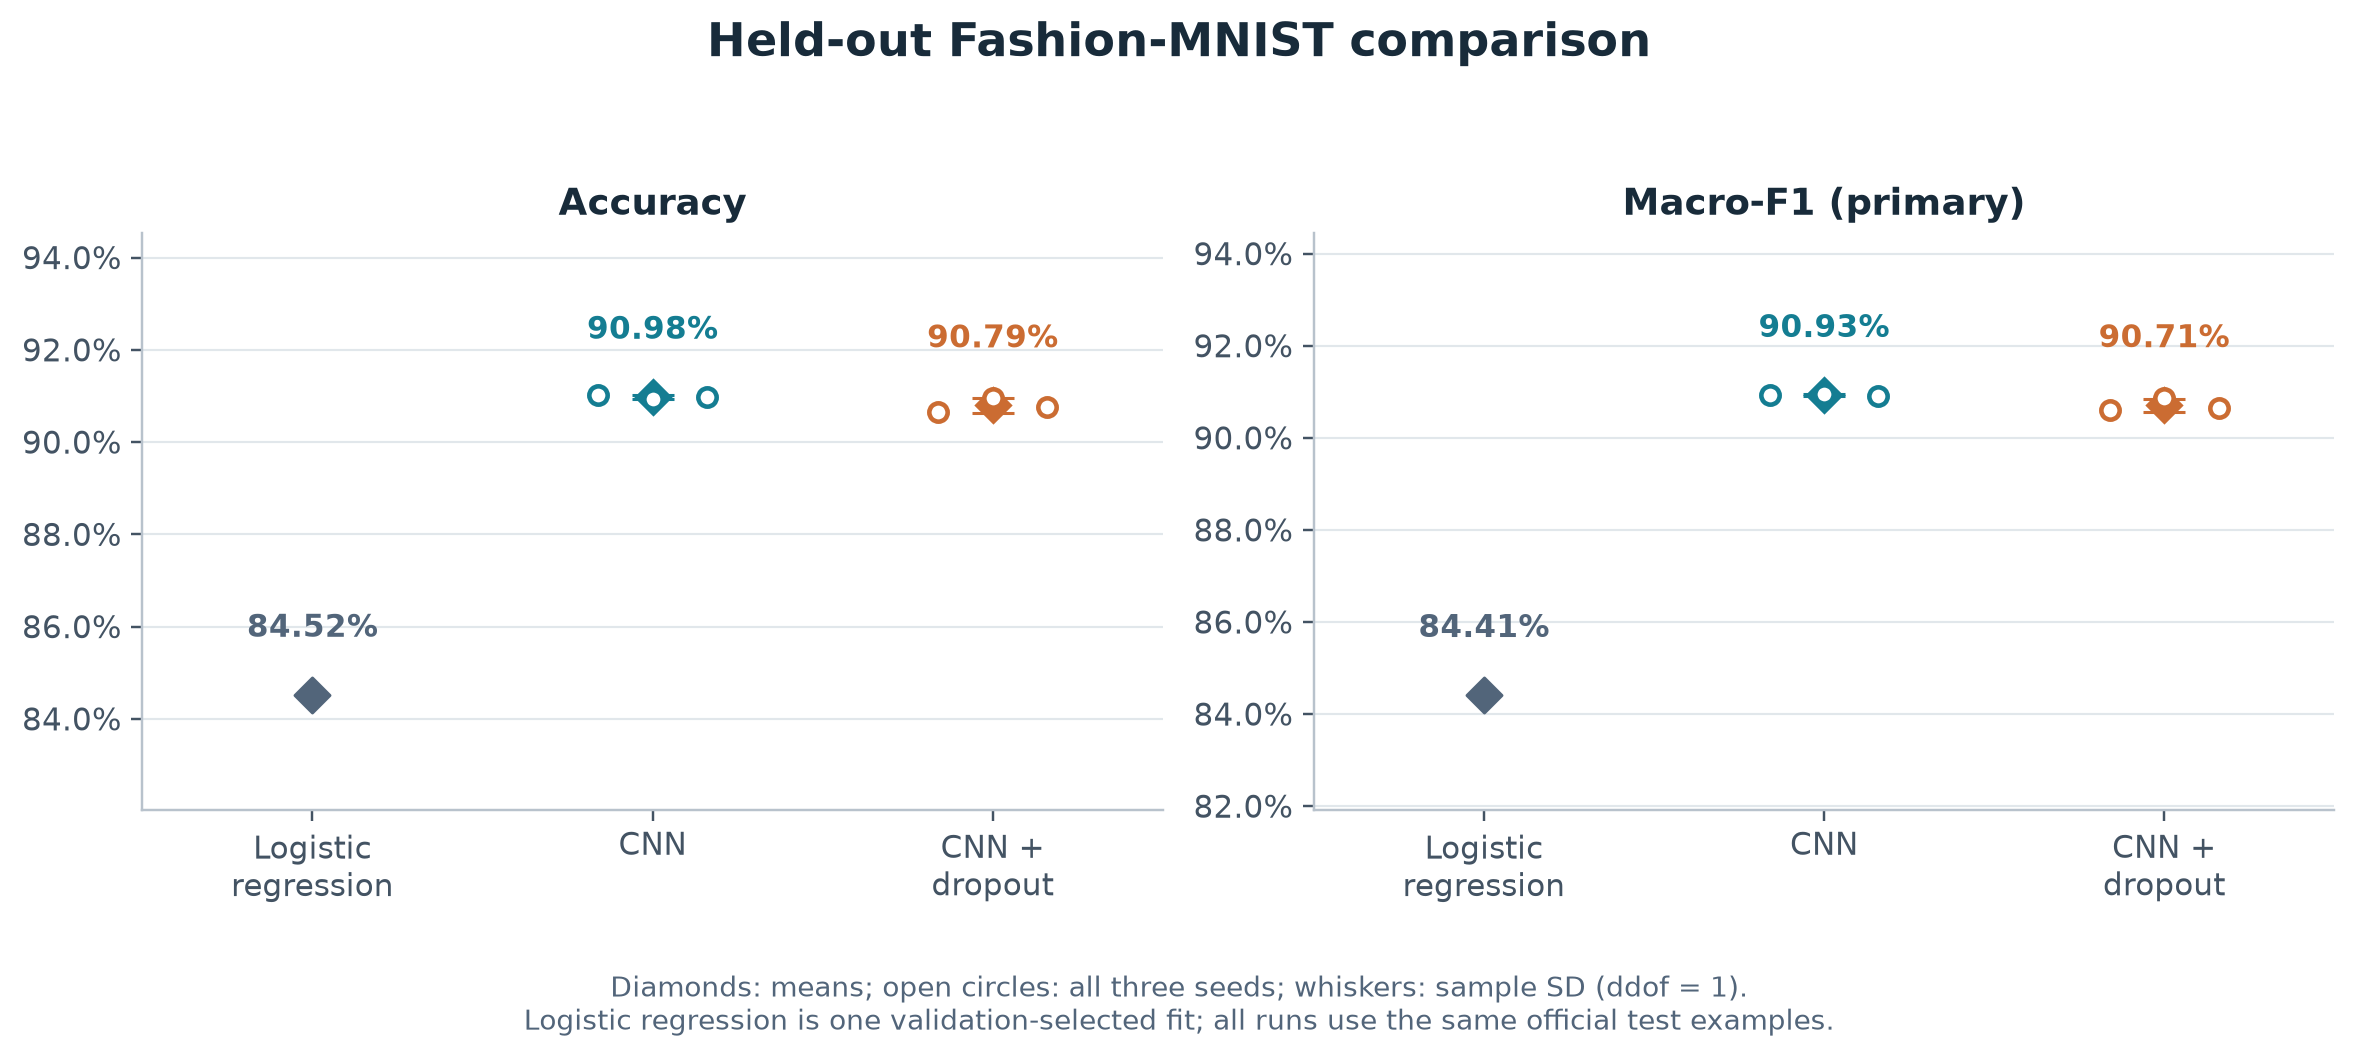

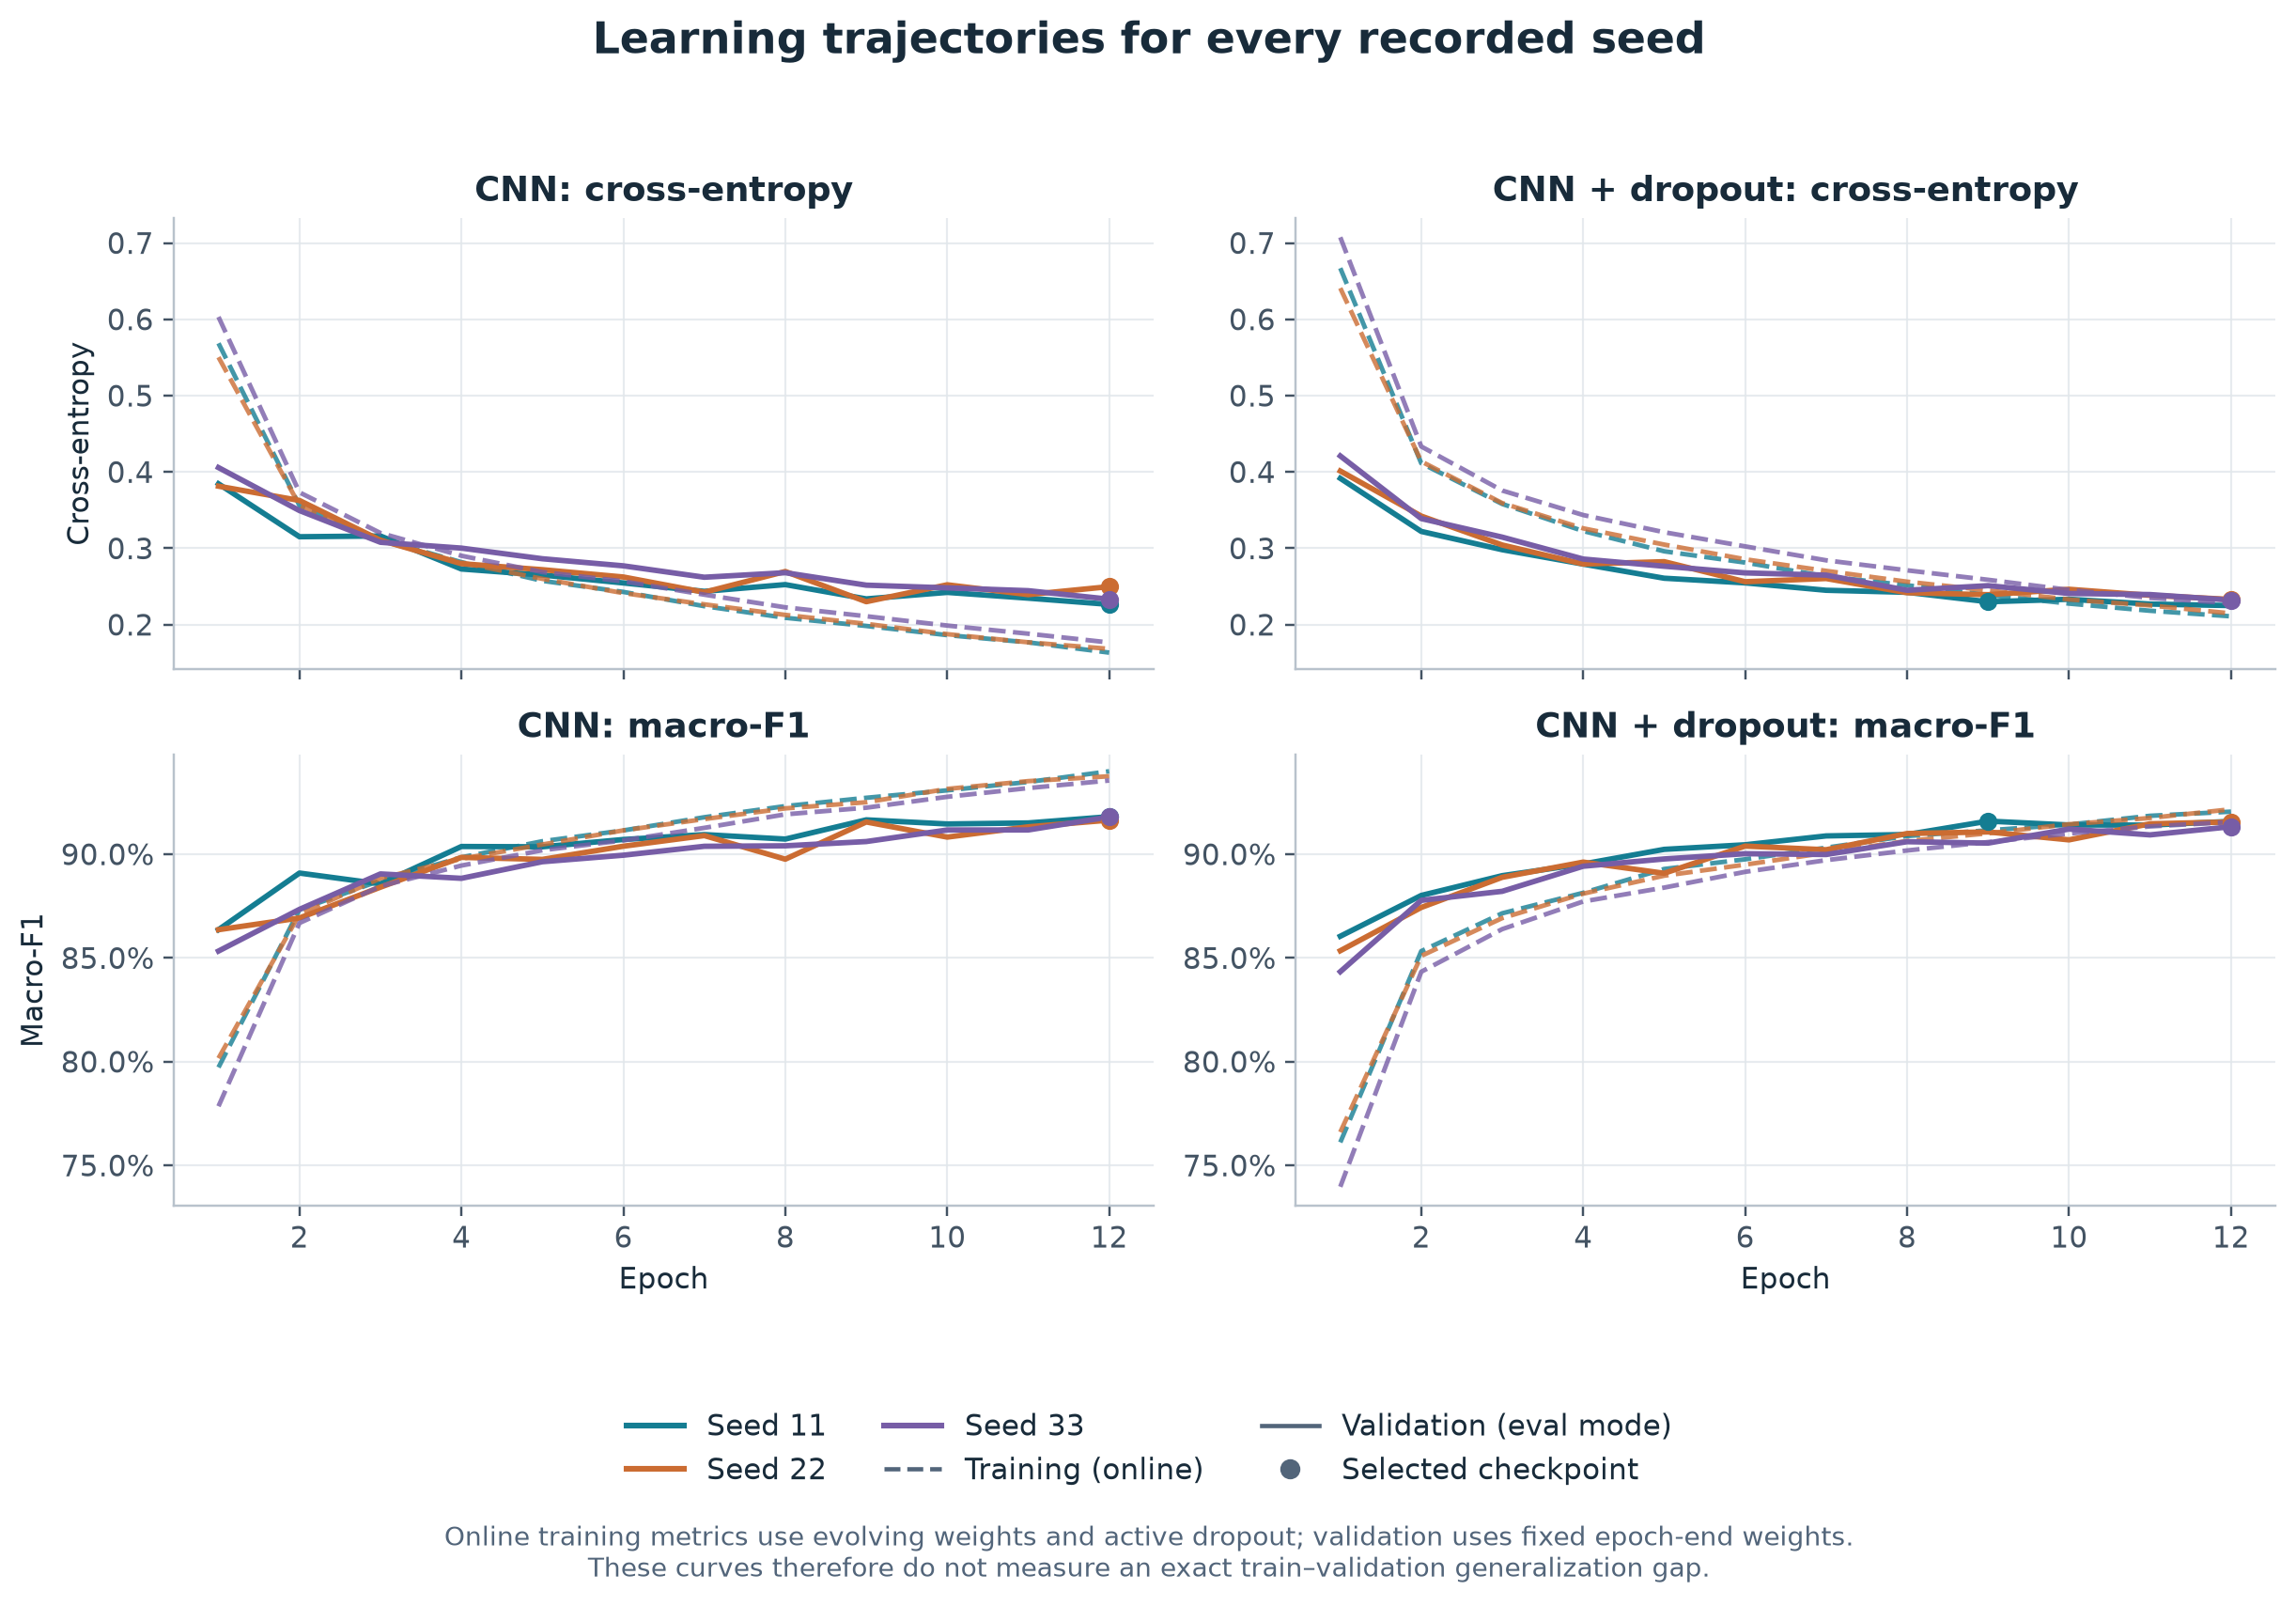

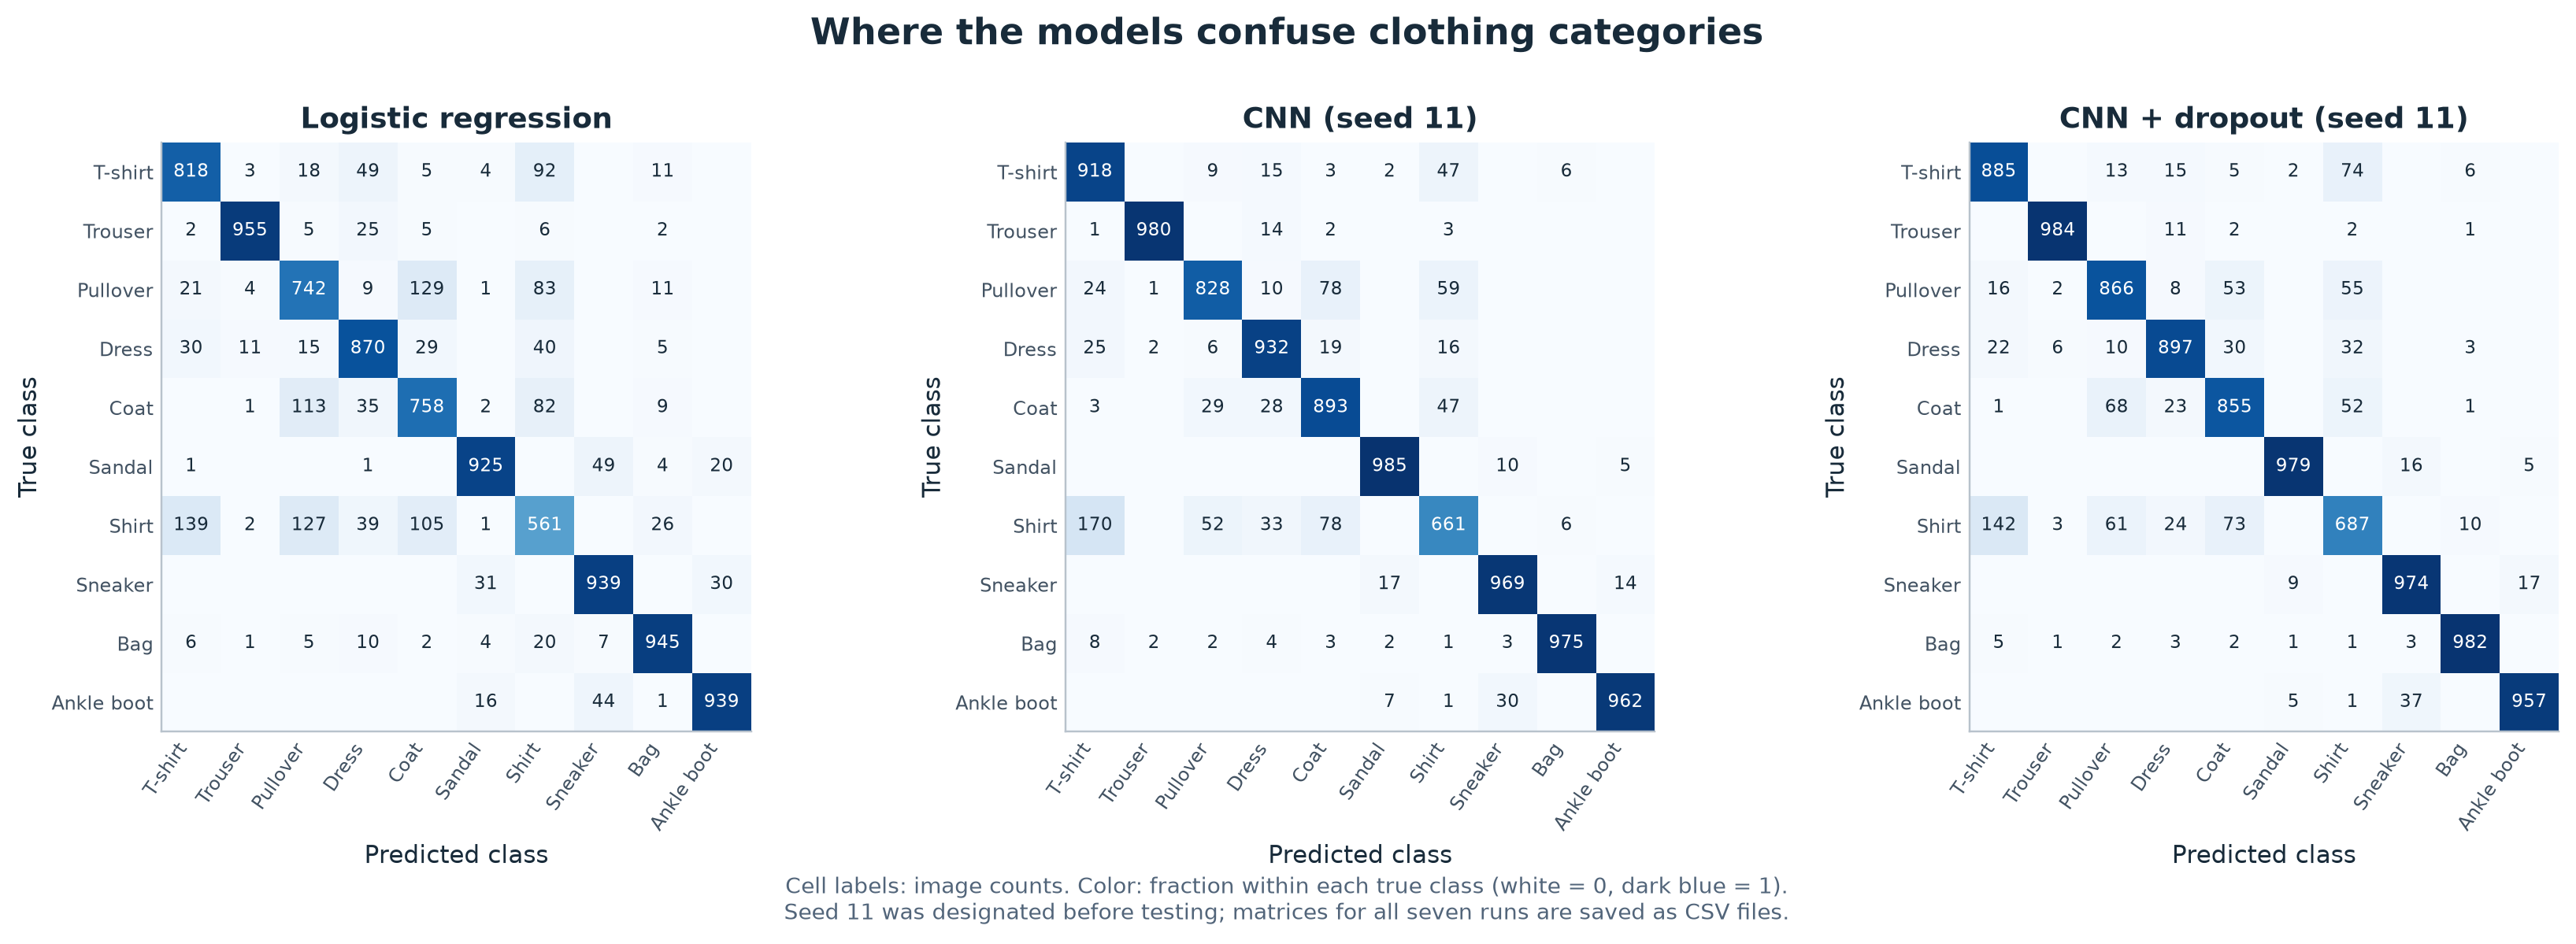

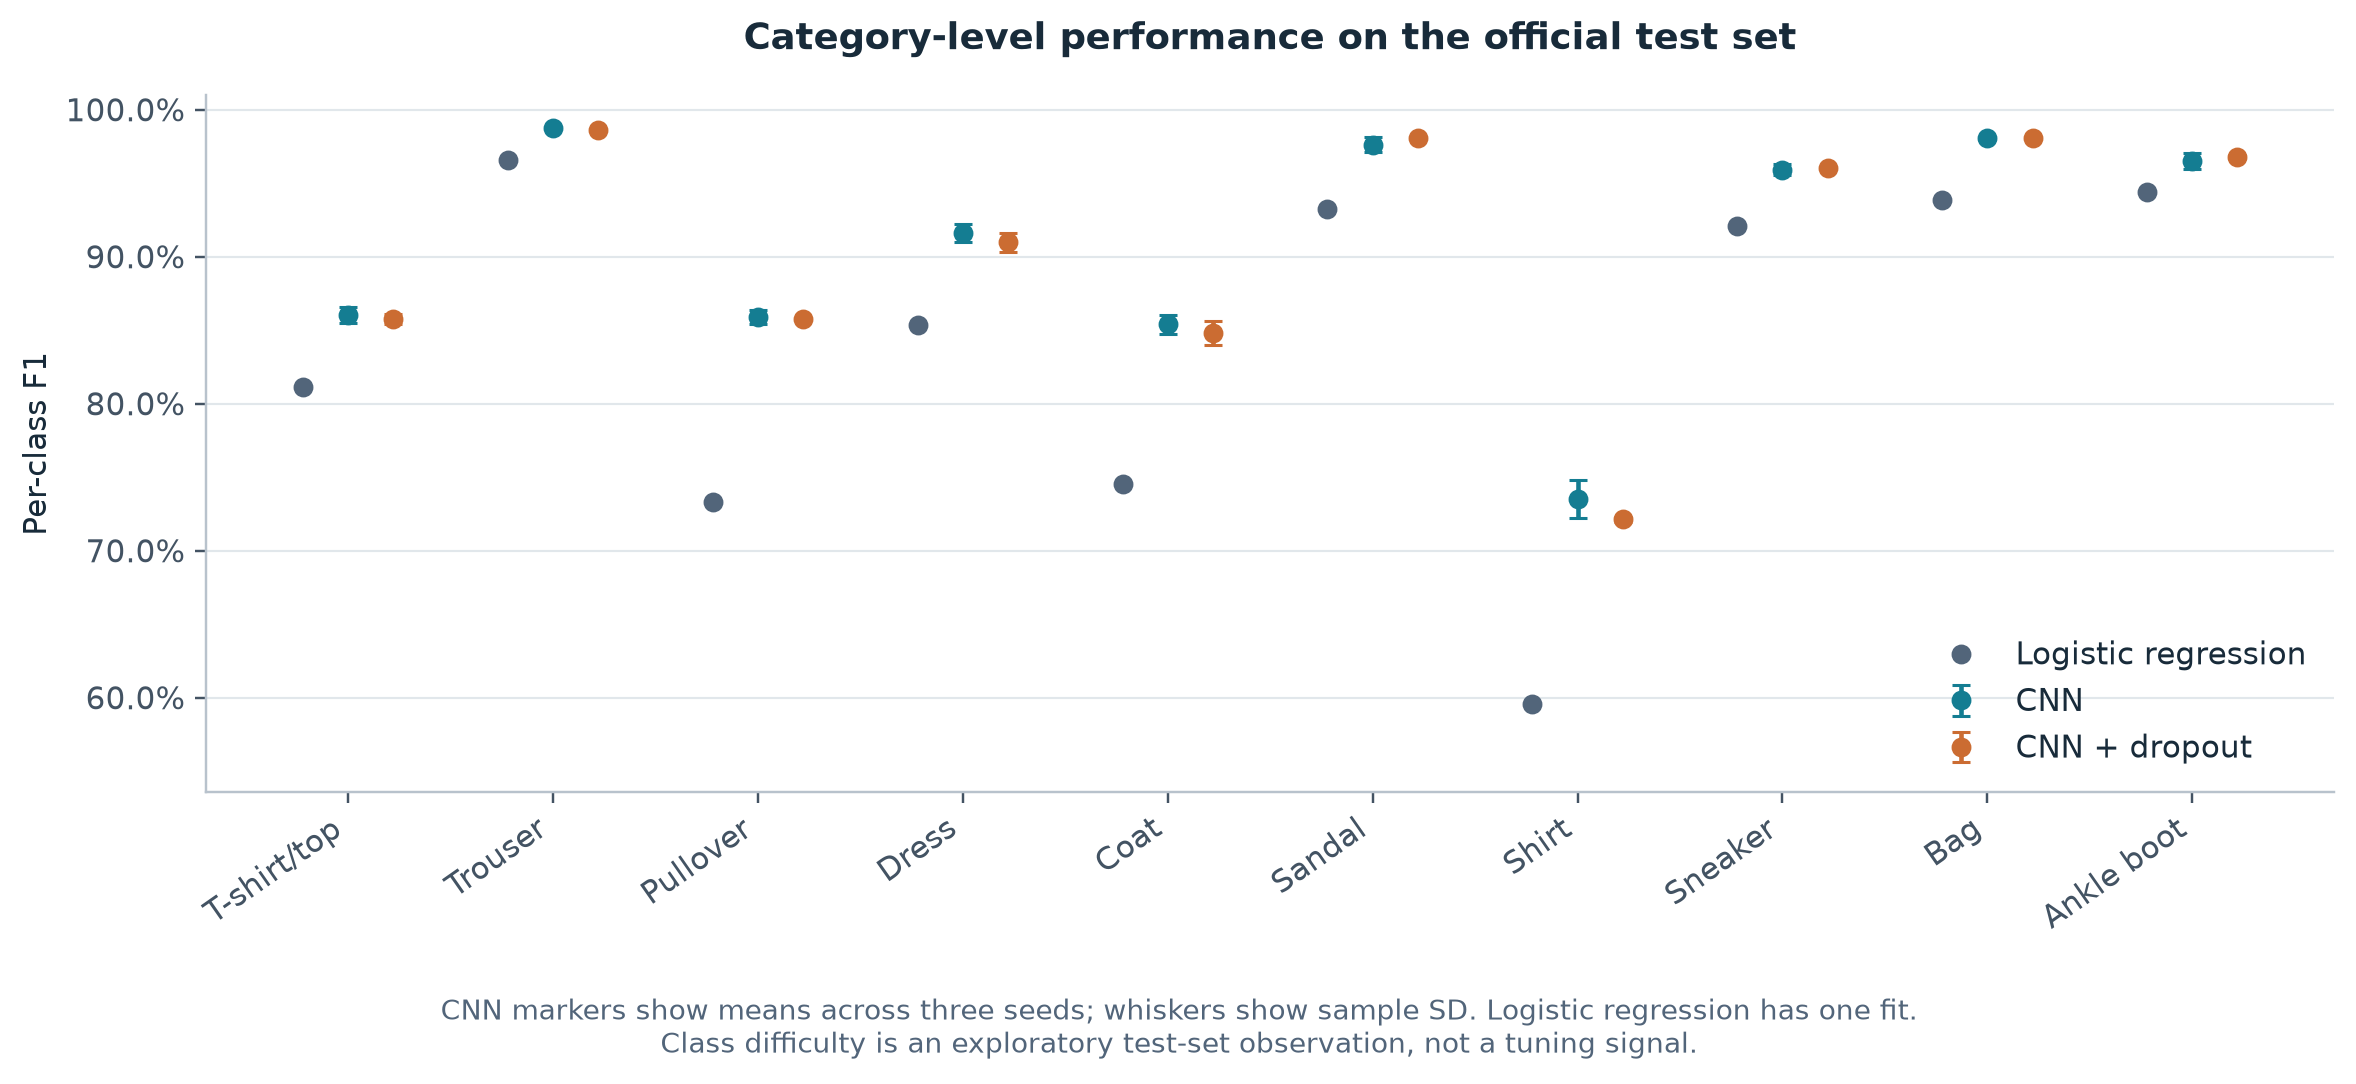

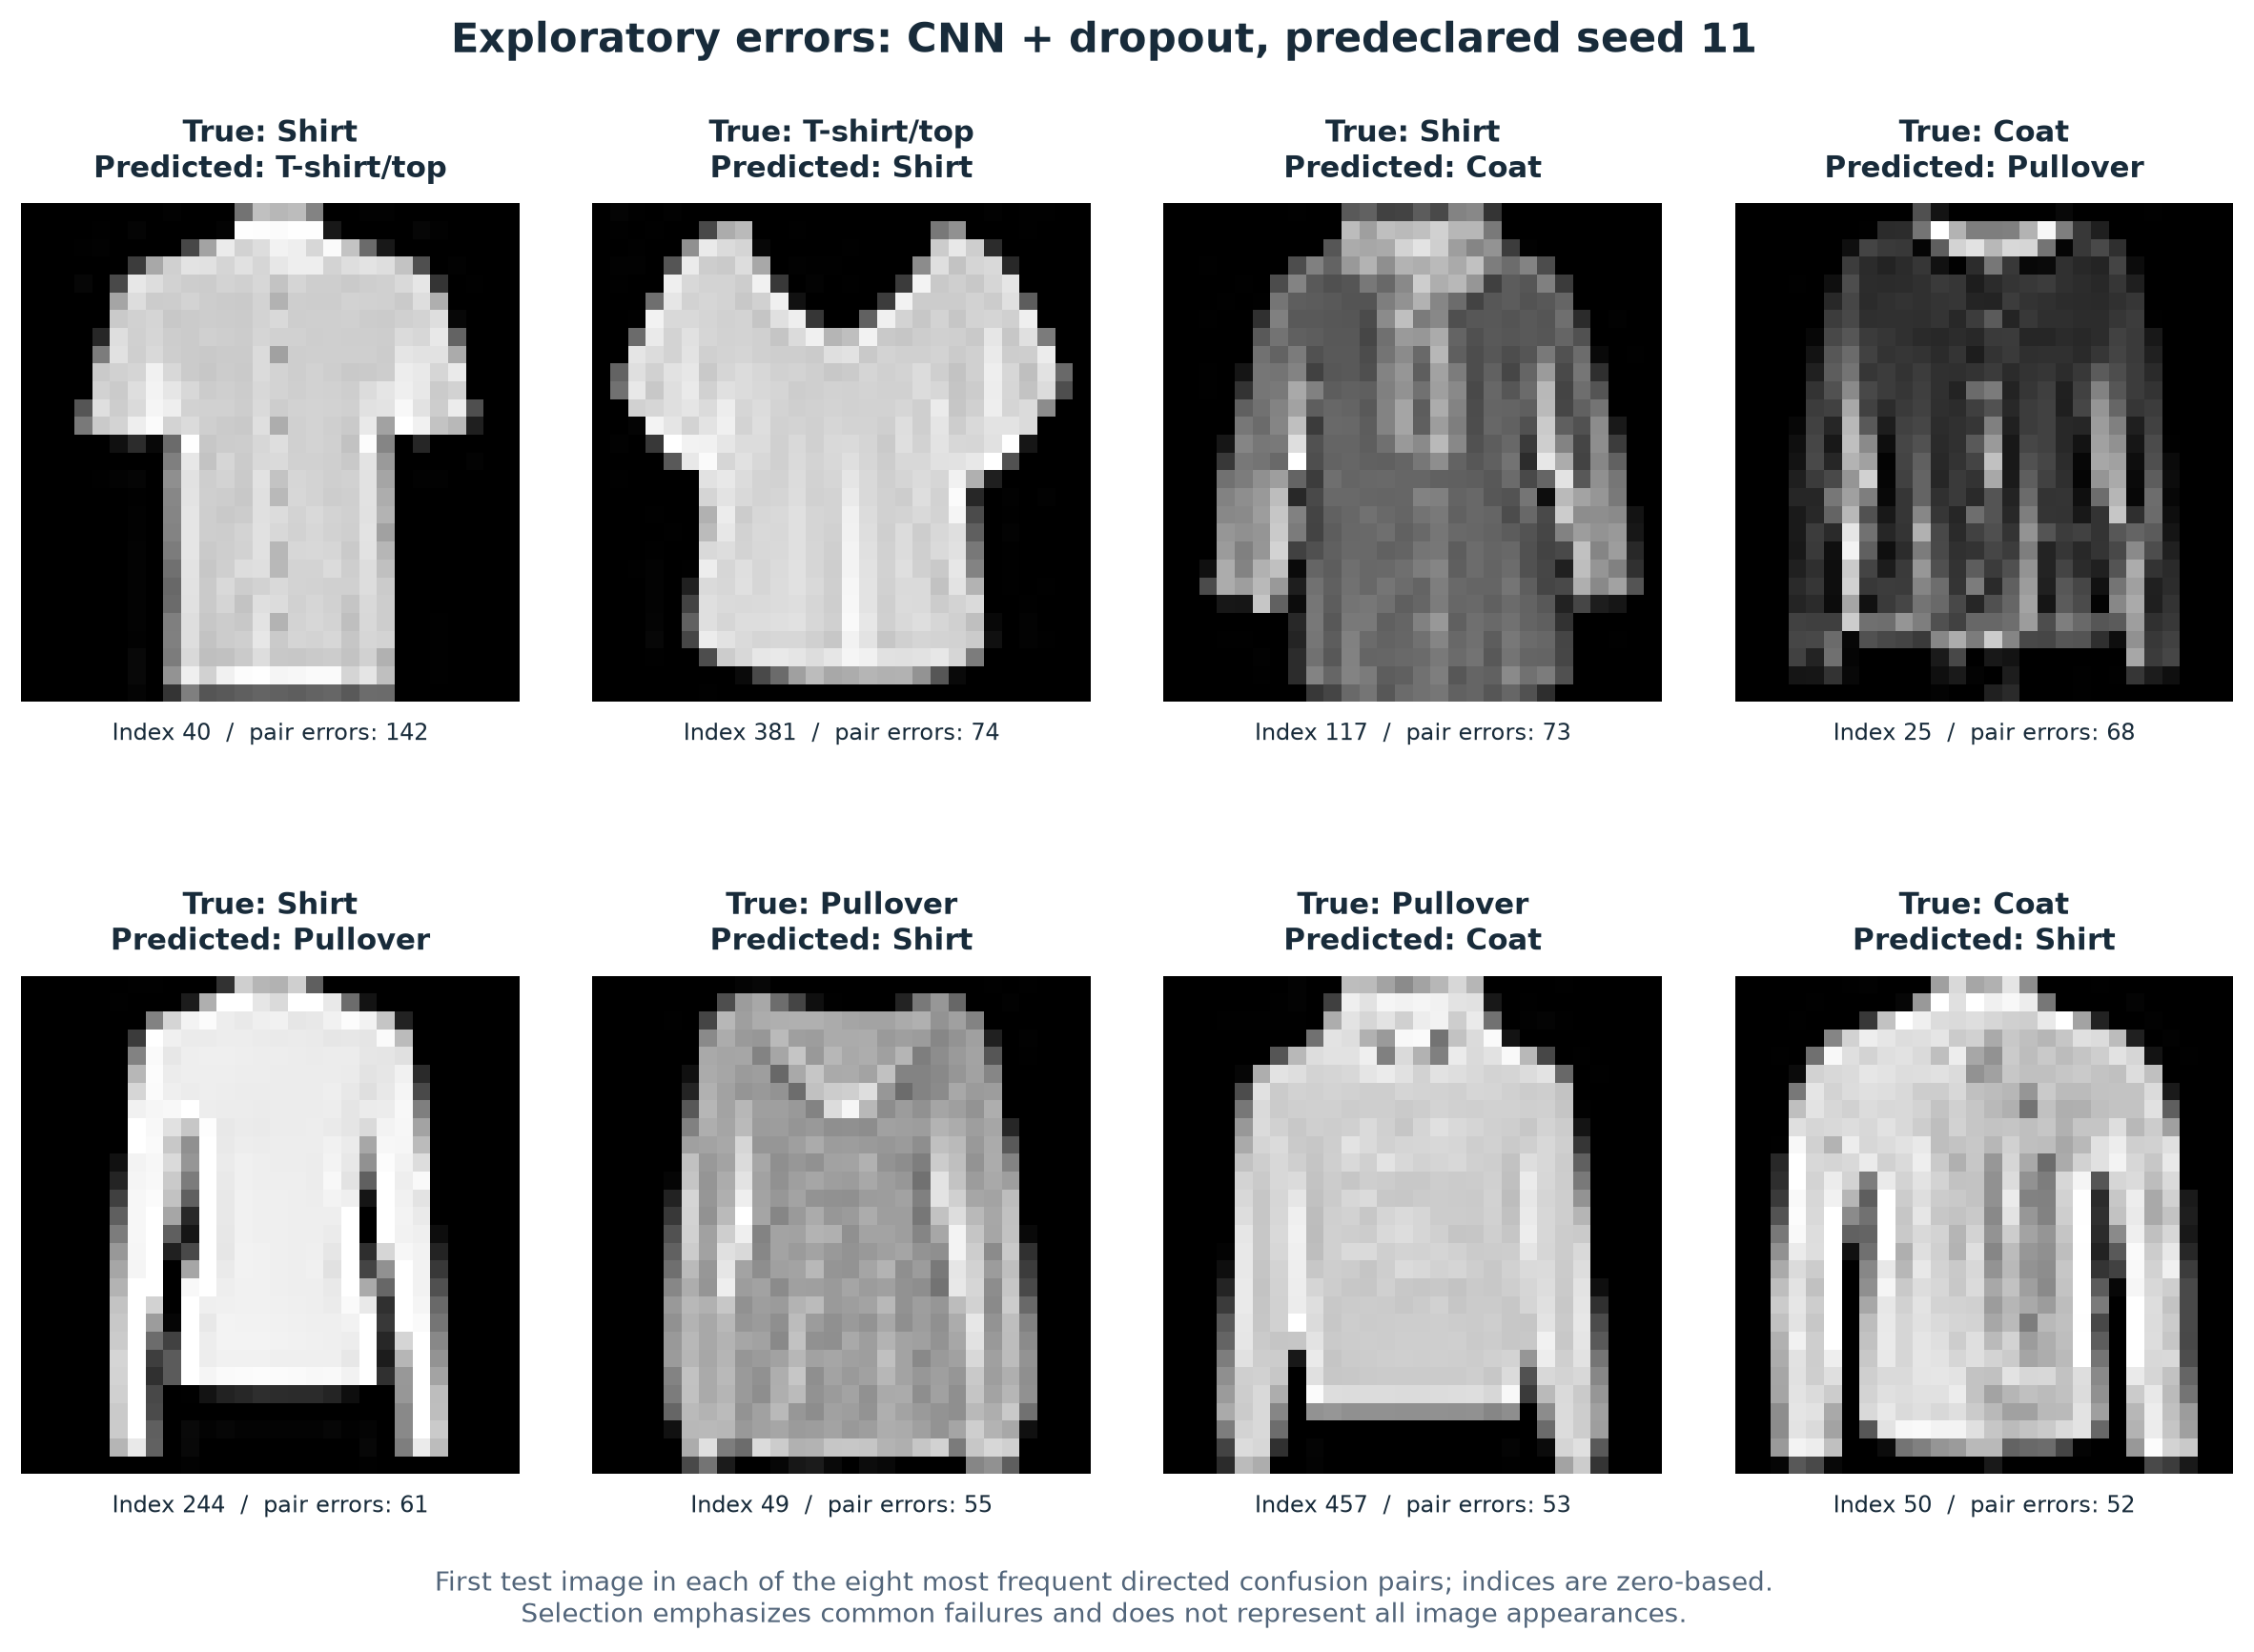

,run,variant,seed,true_class_id,true_class,predicted_class_id,predicted_class,count,fraction_of_true_class
0,cnn_11,cnn,11.0,6,Shirt,0,T-shirt/top,170,0.170
1,cnn_11,cnn,11.0,2,Pullover,4,Coat,78,0.078
2,cnn_11,cnn,11.0,6,Shirt,4,Coat,78,0.078
3,cnn_11,cnn,11.0,2,Pullover,6,Shirt,59,0.059
4,cnn_11,cnn,11.0,6,Shirt,2,Pullover,52,0.052
5,cnn_11,cnn,11.0,0,T-shirt/top,6,Shirt,47,0.047
6,cnn_11,cnn,11.0,4,Coat,6,Shirt,47,0.047
7,cnn_11,cnn,11.0,6,Shirt,3,Dress,33,0.033
8,cnn_11,cnn,11.0,9,Ankle boot,7,Sneaker,30,0.030
9,cnn_11,cnn,11.0,4,Coat,2,Pullover,29,0.029


In [8]:
import runpy
runpy.run_path(str(ROOT/'scripts/refine_figures.py'))
for figure in ['comparison','learning_curves','confusion_matrices','class_f1','representative_errors']:
    display(Image(filename=str(ROOT/f'figures/{figure}.png')))
display(pd.read_csv(ROOT/'results/error_pairs.csv').head(20))

## 8. Interpretation and limitations

The completed interpretation is grounded in the tables and images above and the report. Error examples and garment-shape explanations formed after inspecting the test set are **exploratory**. Fashion-MNIST is low-resolution grayscale catalog imagery; performance does not establish accuracy on real camera photos, new clothing sources or demographic groups. Exact deduplication cannot detect every related item. A single split, one dropout rate, one CNN size and a fixed budget limit generalization. Three seeds quantify training variability only.

No pretrained weights or external training data are used. The baseline and neural models use the same examples and normalization but have different representation families; the controlled causal comparison is CNN versus CNN plus dropout. Code was prepared with AI assistance; team members must review and understand it and supply their actual names and contributions. Recording and Moodle submission remain pending.